In [ ]:
!pip install openai pandas

In [ ]:
from openai import OpenAI
import os
import json
import re
import requests
from google.colab import userdata
from helpers.utils import processar_lotes, plot_confusion

In [ ]:
os.environ['OPENROUTER_APY_KEY'] = userdata.get('OPENROUTER_APY_KEY')

openai_api_key = os.getenv("OPENROUTER_APY_KEY")

In [ ]:
import google.generativeai as genai

os.environ['GOOGLE_API_KEY'] = userdata.get('GOOGLE_API_KEY')
genai.configure(api_key=os.environ['GOOGLE_API_KEY'])

#Definindo o modelo
model = genai.GenerativeModel("gemini-2.5-pro")

In [ ]:
OPENROUTER_API_URL = "https://openrouter.ai/api/v1/chat/completions"
OPENROUTER_API_KEY = openai_api_key

def classificar_texto(textos, prompt_template, model="x-ai/grok-4-fast:free"):
    prompt = prompt_template
    for idx, t in enumerate(textos, 1):
        prompt += f"{idx}. {t}\n"
    prompt += (
        "\nResponda SOMENTE com 0 ou 1, um por linha, na mesma ordem dos textos fornecidos.\n"
        "Não explique, não justifique, não adicione nada além dos números."
    )

    headers = {
        "Authorization": f"Bearer {OPENROUTER_API_KEY}",
        "Content-Type": "application/json"
    }
    payload = {
        "model": model,
        "messages": [{"role": "user", "content": prompt}],
        "temperature": 0.3,
        "max_tokens": 200
    }

    resp = requests.post(OPENROUTER_API_URL, json=payload, headers=headers)
    resp.raise_for_status()
    resp_json = resp.json()
    # A resposta segue o formato compatível com chat completions
    content = resp_json["choices"][0]["message"]["content"]
    return content.strip(), content.strip()

In [ ]:
def classificar_openrouter_gptoss(textos, prompt_inicial):
    prompt = prompt_inicial + "\n\n"
    for i, texto in enumerate(textos, 1):
        prompt += f"{i}. {texto}\n"
    prompt += (
        "\nResponda SOMENTE com 0 ou 1, um por linha, na mesma ordem dos textos fornecidos.\n"
        "Não explique, não justifique, não adicione nada além dos números."
    )

    url = "https://openrouter.ai/api/v1/chat/completions"
    headers = {
              "Authorization": f"Bearer {openai_api_key}",
              "Content-Type": "application/json",
              }
    data = {
              "model": "openai/gpt-oss-20b:free",
              "messages": [{"role": "user", "content": prompt}],
            }

    resp = requests.post(url, headers=headers, data=json.dumps(data))
    resp.raise_for_status()
    resp = resp.json()
    content = resp["choices"][0]["message"]["content"]

    return content.strip(), content.strip()

In [ ]:
#carregar base de dados
df = pd.read_csv("/content/hate_speech_classification_tcc/dados/Portuguese_Hate_Speech_Dataset/test.csv")
df['label'].value_counts(normalize=True)

,proportion
label,
0,0.7
1,0.3


In [ ]:
zero_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/zero_shot/zero_shot.txt", "r").read()
one_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/one_shot/one_shot.txt", "r").read()
few_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/few_shot/few_shot.txt", "r").read()

## Classificação com modelo DeepSeek V3.1(free)

In [ ]:
client = OpenAI(
  base_url="https://openrouter.ai/api/v1",
  api_key=openai_api_key,
)

def classificar_deepSeek(textos, prompt_template):

    prompt = prompt_template + "\n\n"
    for i, texto in enumerate(textos, 1):
        prompt += f"{i}. {texto}\n"
    prompt += (
        "\nResponda SOMENTE com 0 ou 1, um por linha, na mesma ordem dos textos fornecidos.\n"
        "Não explique, não justifique, não adicione nada além dos números."
    )

    completion = client.chat.completions.create(
        model="deepseek/deepseek-chat-v3.1:free",
        messages=[
          {
            "role": "user",
            "content": prompt
          }
        ]
      )
    resp = completion.choices[0].message.content

    return resp.strip(), resp.strip()

In [ ]:
prompt_name = 'pred_zero_shot'
prompt_template = zero_shot_prompt

df_final = df.copy()
df_final[prompt_name] = None
df_final[f'{prompt_name}_raw'] = None
print(f"classificação com: {prompt_name}")

batch_size = 20
for i in range(0, len(df), batch_size):
    try:
        lote = df_final.iloc[i:i+batch_size]["text"].tolist()
        saida, raw_saida = classificar_deepSeek(lote, prompt_template)

        resultados = parse_saida(saida, len(lote))
        raw_resultados = raw_saida.split("\n")

        for j, res in enumerate(resultados):
            idx = i + j
            if idx < len(df):
                if res in ["0", "1"]:
                    df_final.at[idx, prompt_name] = int(res)
                else:
                    df_final.at[idx, prompt_name] = None
                df_final.at[idx, f'{prompt_name}_raw'] = raw_resultados[j] if j < len(raw_resultados) else None

        time.sleep(16)

    except Exception as e:
        print(f"Erro no batch {i}–{i+batch_size} for {prompt_name}: {e}")
        time.sleep(15)

df_final.to_csv("resultados_prompts.csv", index=False)
print("✅ Classificação concluída e salva em 'resultados_prompts.csv'")

classificação com: pred_zero_shot
Erro no batch 0–20 for pred_zero_shot: Error code: 429 - {'error': {'message': 'Rate limit exceeded: free-models-per-day. Add 10 credits to unlock 1000 free model requests per day', 'code': 429, 'metadata': {'headers': {'X-RateLimit-Limit': '50', 'X-RateLimit-Remaining': '0', 'X-RateLimit-Reset': '1760400000000'}, 'provider_name': None}}, 'user_id': 'user_33ZL2v88B9abNKk6o8dPwcPXxgS'}


KeyboardInterrupt: 

### Classificação com modelo Tongyi DeepResearch

In [ ]:
client = OpenAI(
base_url="https://openrouter.ai/api/v1",
api_key=openai_api_key,
               )

def classificar_tongyi(textos, prompt_template):

        prompt = prompt_template + "\n\n"
        for i, texto in enumerate(textos, 1):
            prompt += f"{i}. {texto}\n"
        prompt += (
                "\nResponda SOMENTE com 0 ou 1, um por linha, na mesma ordem dos textos fornecidos.\n"
                "Não explique, não justifique, não adicione nada além dos números."
            )

        completion = client.chat.completions.create(

            model="alibaba/tongyi-deepresearch-30b-a3b:free",
            messages=[
                {
                    "role": "user",
                    "content": prompt
                 }
                      ]

            )

        resp = completion.choices[0].message.content

        return resp.strip(), resp.strip()

In [ ]:
# Processar lotes
df_final = processar_lotes(df, model, zero_shot_prompt, 'pred_zero_shot', batch_size=20)

classificação com: pred_zero_shot
✅ Classificação concluída e salva em 'resultados_prompts.csv'


In [ ]:
prompt_name = 'pred_one_shot'
prompt_template = one_shot_prompt

df_final[prompt_name] = None
print(f"classificação com: {prompt_name}")

batch_size = 20
for i in range(0, len(df), batch_size):
    try:
        lote = df_final.iloc[i:i+batch_size]["text"].tolist()
        saida, raw_saida = classificar_tongyi(lote, prompt_template)

        resultados = parse_saida(saida, len(lote))
        raw_resultados = raw_saida.split("\n")

        for j, res in enumerate(resultados):
            idx = i + j
            if idx < len(df):
                if res in ["0", "1"]:
                    df_final.at[idx, prompt_name] = int(res)
                else:
                    df_final.at[idx, prompt_name] = None
                df_final.at[idx, f'{prompt_name}_raw'] = raw_resultados[j] if j < len(raw_resultados) else None

        time.sleep(2)

    except Exception as e:
        print(f"Erro no batch {i}–{i+batch_size} for {prompt_name}: {e}")
        time.sleep(15)

df_final.to_csv("resultados_prompts.csv", index=False)

classificação com: pred_one_shot


In [ ]:
prompt_name = 'pred_few_shot'
prompt_template = few_shot_prompt

df_final[prompt_name] = None
print(f"classificação com: {prompt_name}")

batch_size = 20
for i in range(0, len(df), batch_size):
    try:
        lote = df_final.iloc[i:i+batch_size]["text"].tolist()
        saida, raw_saida = classificar_tongyi(lote, prompt_template)

        resultados = parse_saida(saida, len(lote))
        raw_resultados = raw_saida.split("\n")

        for j, res in enumerate(resultados):
            idx = i + j
            if idx < len(df):
                if res in ["0", "1"]:
                    df_final.at[idx, prompt_name] = int(res)
                else:
                    df_final.at[idx, prompt_name] = None
                df_final.at[idx, f'{prompt_name}_raw'] = raw_resultados[j] if j < len(raw_resultados) else None

        time.sleep(2)

    except Exception as e:
        print(f"Erro no batch {i}–{i+batch_size} for {prompt_name}: {e}")
        time.sleep(15)

df_final.to_csv("resultados_prompts.csv", index=False)

classificação com: pred_few_shot
Erro no batch 0–20 for pred_few_shot: Error code: 429 - {'error': {'message': 'Rate limit exceeded: free-models-per-day. Add 10 credits to unlock 1000 free model requests per day', 'code': 429, 'metadata': {'headers': {'X-RateLimit-Limit': '50', 'X-RateLimit-Remaining': '0', 'X-RateLimit-Reset': '1760400000000'}, 'provider_name': None}}, 'user_id': 'user_33ZL2v88B9abNKk6o8dPwcPXxgS'}


KeyboardInterrupt: 

# Verificando os resultados

In [ ]:
df_final['pred_zero_shot'].value_counts()

,count
pred_zero_shot,
0,140
1,60


In [ ]:
#Verficar todas as respostas que não são None em pred_zero_shot_raw
df_final[df_final['pred_one_shot_raw'].notna()]['pred_one_shot_raw']

,pred_one_shot_raw
0,0
1,0
2,0
3,0
4,0
...,...
195,1
196,1
197,0
198,0


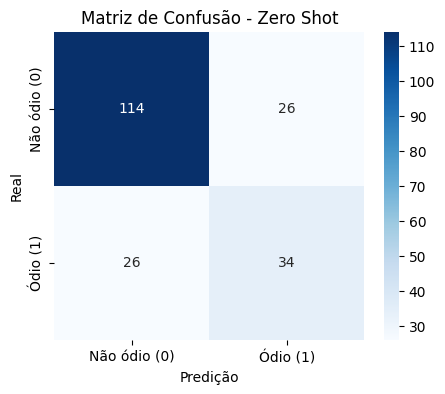


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       140
           1       0.57      0.57      0.57        60

    accuracy                           0.74       200
   macro avg       0.69      0.69      0.69       200
weighted avg       0.74      0.74      0.74       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/report_zero_shot.txt'
plot_confusion(df_final["label"], df_final["pred_zero_shot"].astype(int), "Matriz de Confusão - Zero Shot", path)

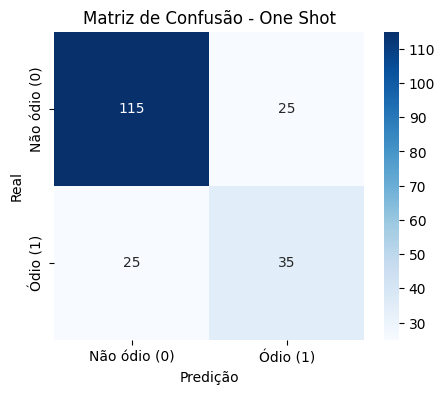


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82       140
           1       0.58      0.58      0.58        60

    accuracy                           0.75       200
   macro avg       0.70      0.70      0.70       200
weighted avg       0.75      0.75      0.75       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/report_one_shot.txt'
plot_confusion(df_final["label"], df_final["pred_one_shot"].astype(int), "Matriz de Confusão - One Shot", path)